In [1]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget
import warnings
warnings.filterwarnings(action='once')
import os
import torch
os.environ['TORCH_CUDA_ARCH_LIST'] = f'{torch.cuda.get_device_properties(0).major}.{torch.cuda.get_device_properties(0).minor}'
from datetime import datetime

import torch

import matplotlib.patches as patches
from mpl_toolkits.axes_grid1 import make_axes_locatable
import torch
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 
from tqdm import TqdmExperimentalWarning
warnings.filterwarnings("ignore", category=TqdmExperimentalWarning)
from tqdm.autonotebook import tqdm

from typing import Union, List
from diffSPH.kernels import getKernel
from diffSPH.v2.sphOps import sphOperation
from diffSPH.v2.math import volumeToSupport

from diffSPH.v2.math import mod
# from torchCompactRadius import radiusSearch
# from torchCompactRadius.util import countUniqueEntries

from diffSPH.v2.sampling import sampleRegular
# from torchCompactRadius import radiusSearch
# from torchCompactRadius.util import countUniqueEntries
from diffSPH.v2.sphOps import sphOperation
from diffSPH.v2.math import mod, volumeToSupport
from diffSPH.kernels import getKernel
from diffSPH.v2.modules.neighborhood import neighborSearch
from diffSPH.v2.sampling import samplePDF
from diffSPH.v2.math import scatter_sum
from diffSPH.v2.shifting import computeShifting
import numpy as np
import torch

from diffSPH.v2.finiteDifference import computeGradient
from diffSPH.v2.sdf import getSDF, sdfFunctions, operatorDict

# def scatterPlot(fig, axis, p, c, domainMin, domainMax, label = None, periodic = True):
#     pos = torch.stack([p[:,i] if not periodic else torch.remainder(p[:,i] - domainMin[i], domainMax[i] - domainMin[i]) + domainMin[i] for i in range(dim)], dim = 1)
#     sc = axis.scatter(pos[:,0], pos[:,1], s = 8, c = c)
#     ax1_divider = make_axes_locatable(axis)
#     cax1 = ax1_divider.append_axes("right", size="4%", pad="1%")
#     cb = fig.colorbar(sc, cax=cax1,orientation='vertical')
#     if label is not None:
#         axis.set_title(label)
#     if p.shape[1] > 1:
#         square = patches.Rectangle((domainMin[0], domainMin[1]), domainMax[0] - domainMin[0], domainMax[1] - domainMin[1], linewidth=1, edgecolor='b', facecolor='none',ls='--')
#         axis.add_patch(square)
#     axis.set_aspect('equal')
#     axis.set_xlim(domainMin[0] * 1.05, domainMax[0] * 1.05)
#     axis.set_ylim(domainMin[1] * 1.05, domainMax[1] * 1.05)

# def scatterPlotSymmetric(fig, axis, p, c, domainMin, domainMax, label = None, periodic = True):
#     pos_x = torch.stack([p[:,i] if not periodic else torch.remainder(p[:,i] - domainMin[i], domainMax[i] - domainMin[i]) + domainMin[i] for i in range(dim)], dim = 1)
#     # pos_y = torch.stack([y[:,i] if not periodic_i else torch.remainder(y[:,i] - minDomain[i], maxDomain[i] - minDomain[i]) + minDomain[i] for i, periodic_i in enumerate(periodicity)], dim = 1)

#     sc = axis.scatter(pos_x[:,0], pos_x[:,1], s = 8, c = c, vmin = -c.abs().max(), vmax = c.abs().max(), cmap = 'Spectral')
#     ax1_divider = make_axes_locatable(axis)
#     cax1 = ax1_divider.append_axes("right", size="4%", pad="1%")
#     cb = fig.colorbar(sc, cax=cax1,orientation='vertical')
#     if label is not None:
#         axis.set_title(label)
#     if p.shape[1] > 1:
#         square = patches.Rectangle((domainMin[0], domainMin[1]), domainMax[0] - domainMin[0], domainMax[1] - domainMin[1], linewidth=1, edgecolor='b', facecolor='none',ls='--')
#         axis.add_patch(square)
#     axis.set_aspect('equal')
#     axis.set_xlim(-1.05,1.05)
#     axis.set_ylim(-1.05,1.05)

In [2]:
%matplotlib widget
from diffSPH.v2.parameters import parseDefaultParameters, parseModuleParameters
from diffSPH.v2.modules.neighborhood import neighborSearch
from diffSPH.v2.sphOps import sphOperationStates
from diffSPH.v2.util import countUniqueEntries
from diffSPH.v2.plotting import plotImplicitSDF
from diffSPH.v2.modules.surfaceDetection import computeColorField, computeColorFieldGradient
from diffSPH.v2.modules.surfaceDetection import detectFreeSurfaceColorFieldGradient
import matplotlib.pyplot as plt
import torch
import numpy as np
from diffSPH.v2.sdf import getSDF, sdfFunctions, operatorDict

config = {
    'domain': {
        'minExtent': -1,
        'maxExtent': 1,
        'dim': 2,
        'periodic': True
    },
    'particle': {
        'nx': 128
    },
    'kernel':{
        'name': 'Wendland2',
    'targetNeighbors': 45.22,
    },
    "neighborhood":{
        "scheme": "compact",
        'verletScale': 1.5
    },
    'EOS':{
        'type': 'Tait',
        'kappa': 1.5
    },
    'shifting':{
        'freeSurface': True
    },
    'diffusion':{
        'nu' : 0.002,
        'alpha':0.01,
        'velocityScheme': 'deltaSPH_inviscid'
    },
    'timestep':{'dt': 0.001}
}

config = parseDefaultParameters(config)
config = parseModuleParameters(config)

display(config)

{'domain': {'minExtent': tensor([-1., -1.]),
  'maxExtent': tensor([1., 1.]),
  'dim': 2,
  'periodic': True,
  'periodicity': tensor([True, True])},
 'particle': {'nx': 128,
  'dx': tensor(0.0156),
  'kernelScale': tensor(1.8970),
  'defaultVolume': tensor(0.0002),
  'defaultSupport': 0.05928029670513617,
  'volume': tensor(0.0002),
  'support': 0.05928029670513617,
  'smoothingLength': tensor(0.0312)},
 'kernel': {'name': 'Wendland2',
  'targetNeighbors': 45.22,
  'function': <diffSPH.kernels.KernelWrapper at 0x7d375649d400>,
  'kernelScale': tensor(1.8970)},
 'neighborhood': {'scheme': 'compact', 'verletScale': 1.5},
 'EOS': {'type': 'Tait',
  'kappa': 1.5,
  'gasConstant': 8.14,
  'molarMass': 0.02897,
  'polytropicExponent': 7},
 'shifting': {'freeSurface': True,
  'scheme': 'deltaSPH',
  'R': 0.25,
  'n': 4,
  'CFL': 1.5,
  'computeMach': True,
  'solver': 'BiCGStab_wJacobi',
  'normalScheme': 'lambda',
  'projectionScheme': 'mat',
  'threshold': 0.5,
  'surfaceScaling': 0.1,
  '

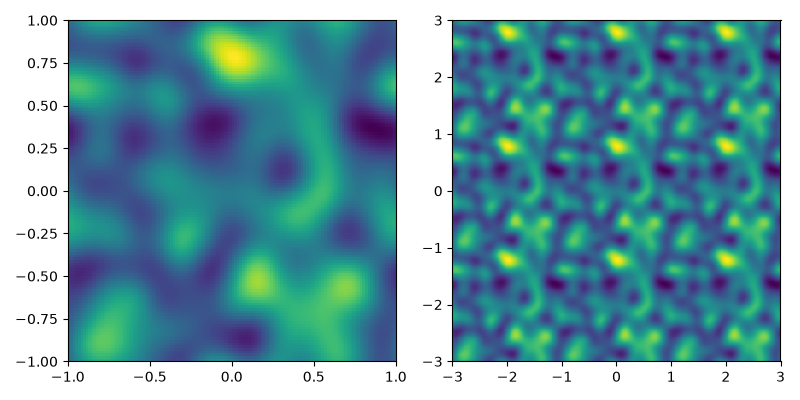

In [3]:
from diffSPH.v2.plotting import *
from diffSPH.noise.generator import generatePerlin, generateSimplex, generateOctaveNoise
from diffSPH.v2.noise import generateNoise

*grid, noiseSimplex = generateNoise(n = 128, baseFrequency= 3, dim = 2, octaves = 1, persistence = 0.5, lacunarity = 2.0, seed = 23467586, tileable=True, kind = 'simplex')
fig, axis = plt.subplots(1, 2, figsize=(8,4), sharex = False, sharey = False, squeeze = False)
xx, yy = [g.detach().cpu().numpy() for g in grid]
axis[0,0].pcolormesh(xx, yy, noiseSimplex.detach().cpu().numpy(), cmap = 'viridis')
for xoffset in [-1,0,1]:
    for yoffset in [-1,0,1]:
        axis[0,1].pcolormesh(xx + xoffset * 2, yy + yoffset * 2, noiseSimplex.detach().cpu().numpy(), cmap = 'viridis')
fig.tight_layout()

In [4]:
from diffSPH.v2.sampling import sampleParticles
import copy
fluidState, mask = sampleParticles(config)
particleState = {
    'fluid': fluidState,
    'time': 0,
    'timestep': 0,
    'dt': config['timestep']['dt']
}
initialState = copy.deepcopy(particleState)
print(fluidState['positions'].shape)

torch.Size([16384, 2])


In [5]:

def scatterPlot(fig, axis, p, c, domainMin, domainMax, label = None, cmap = 'viridis', s = None,periodic = True):
    s = 5000 / p.shape[0] if s is None else s
    dim = p.shape[1]
    pos_x = torch.stack([p[:,i] if not periodic else torch.remainder(p[:,i] - domainMin[i], domainMax[i] - domainMin[i]) + domainMin[i] for i in range(dim)], dim = 1)
    

    sc = axis.scatter(pos_x[:,0], pos_x[:,1], s = s, c = c, cmap = cmap)
    ax1_divider = make_axes_locatable(axis)
    cax1 = ax1_divider.append_axes("right", size="4%", pad="1%")
    cb = fig.colorbar(sc, cax=cax1,orientation='vertical')
    if label is not None:
        axis.set_title(label)
    if p.shape[1] > 1:
        square = patches.Rectangle((domainMin[0], domainMin[1]), domainMax[0] - domainMin[0], domainMax[1] - domainMin[1], linewidth=1, edgecolor='b', facecolor='none',ls='--')
        axis.add_patch(square)
    axis.set_aspect('equal')
    axis.set_xlim(domainMin[0] * 1.05, domainMax[0] * 1.05)
    axis.set_ylim(domainMin[1] * 1.05, domainMax[1] * 1.05)

In [6]:
config['shifting']['BiCG'] = False

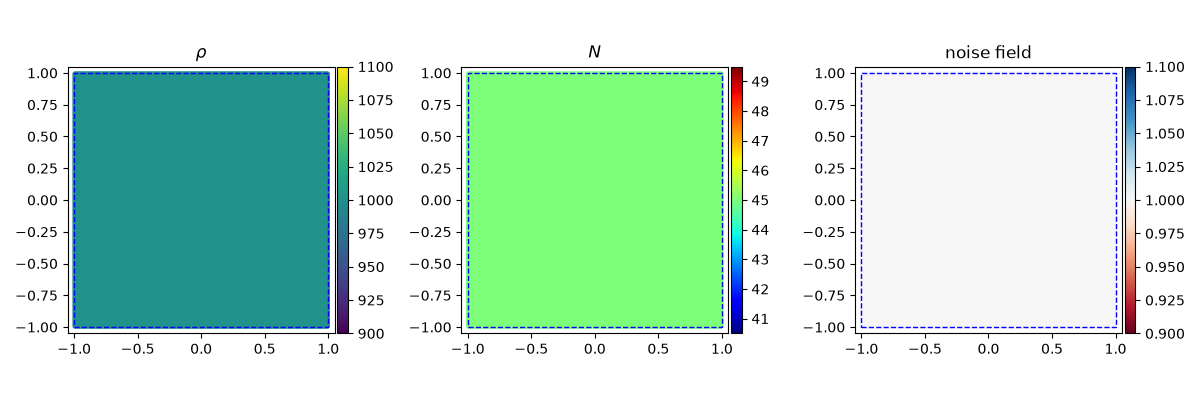

In [7]:

fig, axis = plt.subplots(1, 3, figsize=(12,4), sharex = False, sharey = False, squeeze = False)
scatterPlot(fig, axis[0,0], particleState['fluid']['positions'], particleState['fluid']['densities'], config['domain']['minExtent'], config['domain']['maxExtent'], '$\\rho$', cmap = 'viridis', s = 8)
scatterPlot(fig, axis[0,1], particleState['fluid']['positions'], particleState['fluid']['numNeighbors'], config['domain']['minExtent'], config['domain']['maxExtent'], '$N$', cmap = 'jet', s = 8)
scatterPlot(fig, axis[0,2], particleState['fluid']['positions'], mask.to(torch.int32), config['domain']['minExtent'], config['domain']['maxExtent'], 'noise field', cmap = 'RdBu', s = 8)
for ax in axis.flatten():
    ax.set_xlim(config['domain']['minExtent'][0]-0.05, config['domain']['maxExtent'][0]+ 0.05)
    ax.set_ylim(config['domain']['minExtent'][1]-0.05, config['domain']['maxExtent'][1]+ 0.05)


fig.tight_layout()

Given a kernel:
$$ W(x_i - x_j, y_i - y_j, h) = C_d h^{-d} f\left(\frac{\sqrt{\left(x_i - x_j\right)^2 + \left(y_i -y_j\right)^2}}{h}\right)$$

For convenience denote $q_{ij} = \frac{\sqrt{\left(x_i - x_j\right)^2 + \left(y_i -y_j\right)^2}}{h}$ and $r_{ij} = \sqrt{\left(x_i - x_j\right)^2 + \left(y_i -y_j\right)^2}$

We need the first derivatives w.r.t. x_j and y_j, i.e., $ \frac{\partial W}{\partial x_j}$ and $\frac{\partial W}{\partial y_j}$. Using [Wolfram](https://www.wolframalpha.com/input?i=d%2Fdx+f%28%5Csqrt%28%28a-x%29%5E2+%2B+%28b-y%29%5E2%29%2Fh%29) we get:

$$ \frac{\partial W}{\partial x_j} = \frac{x_i - x_j}{r_{ij}} C_d h^{-(d+1)} f^\prime(q_{ij}) $$
and
$$ \frac{\partial W}{\partial x_j} = \frac{y_i - y_j}{r_{ij}} C_d h^{-(d+1)} f^\prime(q_{ij}) $$



For the second derivatives we get more complex terms for $\frac{\partial^2}{\partial x^2}$ ([Wolfram](https://www.wolframalpha.com/input?i=d%5E2%2F%28dx%5E2%29+f%28%5Csqrt%28%28a-x%29%5E2+%2B+%28b-y%29%5E2%29%2Fh%29)):

$$ \frac{\partial^2}{\partial x^2} W = C_d h^{-d} \cdot \left[
    \frac{\left(x_i - x_j\right)^2}{h^2 r_{ij}^2} f^{\prime\prime}(q_{ij}) +\left(\frac{1}{h r_{ij}} - \frac{\left(x_i - x_j\right)^2}{h r_{ij}^{3}}\right)f^\prime(q_{ij}) \right]
$$



And for the diagonal terms: [Wolfram](https://www.wolframalpha.com/input?i=d%5E2%2F%28dxdy%29+f%28%5Csqrt%28%28a-x%29%5E2+%2B+%28b-y%29%5E2%29%2Fh%29):

$$\frac{\partial^2}{\partial x\partial y} W = C_d h^{-d} \frac{\left(x_i - x_j\right)\left(y_i - y_j\right)}{h r_{ij}^2} \cdot \left[ \frac{1}{h} f^{\prime\prime}(q_{ij}) - \frac{1}{r_{ij}} f^\prime(q_{ij})\right]$$

In [8]:
from diffSPH.v2.shifting import evalKernel

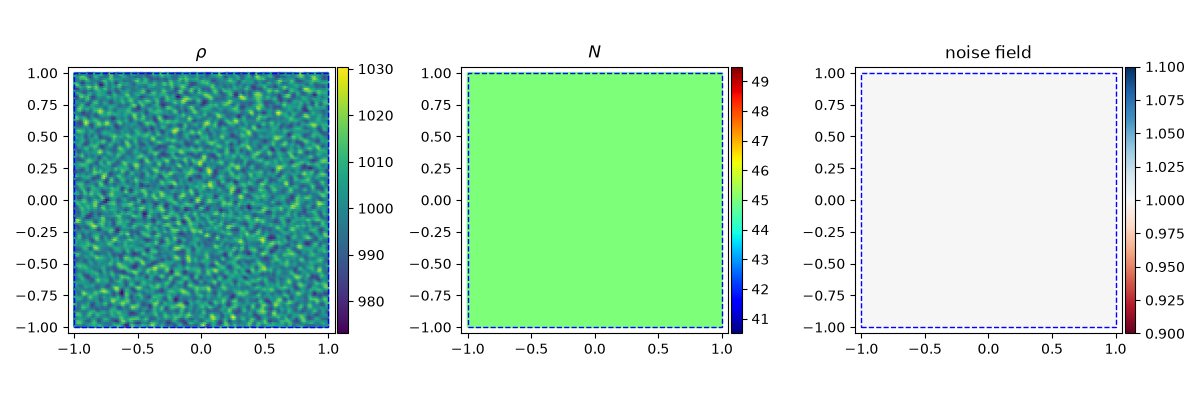

In [9]:
particleState = copy.deepcopy(initialState)
jitter = torch.normal(0, config['particle']['support'], particleState['fluid']['positions'].shape)

jitter = torch.rand(particleState['fluid']['positions'].shape) * config['particle']['dx'] - config['particle']['dx'] * 0.5

particleState['fluid']['positions'] += jitter * 0.1

from diffSPH.v2.modules.neighborhood import searchNeighbors
searchNeighbors(particleState, config)

# particleState['fluid']['positions'] = torch.rand(particleState['fluid']['positions'].shape) * 2 - 1
initialPositions = torch.clone(particleState['fluid']['positions'])
# particleState['fluid']['neighborhood'] = neighborSearch(particleState['fluid'], particleState['fluid'], config, priorNeighborhood=particleState['fluid']['neighborhood'])
particleState['fluid']['densities'] = sphOperationStates(particleState['fluid'], particleState['fluid'], None, operation = 'density', neighborhood = particleState['fluid']['neighborhood'])
_, particleState['fluid']['numNeighbors'] = countUniqueEntries(particleState['fluid']['neighborhood']['indices'][0], particleState['fluid']['positions'])

fig, axis = plt.subplots(1, 3, figsize=(12,4), sharex = False, sharey = False, squeeze = False)
scatterPlot(fig, axis[0,0], particleState['fluid']['positions'], particleState['fluid']['densities'], config['domain']['minExtent'], config['domain']['maxExtent'], '$\\rho$', cmap = 'viridis', s = 4)
scatterPlot(fig, axis[0,1], particleState['fluid']['positions'], particleState['fluid']['numNeighbors'], config['domain']['minExtent'], config['domain']['maxExtent'], '$N$', cmap = 'jet', s = 4)
scatterPlot(fig, axis[0,2], particleState['fluid']['positions'], mask.to(torch.int32), config['domain']['minExtent'], config['domain']['maxExtent'], 'noise field', cmap = 'RdBu', s = 4)
for ax in axis.flatten():
    ax.set_xlim(config['domain']['minExtent'][0]-0.05, config['domain']['maxExtent'][0]+ 0.05)
    ax.set_ylim(config['domain']['minExtent'][1]-0.05, config['domain']['maxExtent'][1]+ 0.05)
fig.tight_layout()

In [10]:

def plotState(particleState, config):
    _, particleState['fluid']['neighborhood'] = neighborSearch(particleState['fluid'], particleState['fluid'], config)
    particleState['fluid']['densities']  = sphOperationStates(particleState['fluid'], particleState['fluid'], quantities = (torch.ones_like(particleState['fluid']['densities']), torch.ones_like(particleState['fluid']['densities'])), operation = 'density', neighborhood = particleState['fluid']['neighborhood'])

    ones = sphOperationStates(particleState['fluid'],particleState['fluid'], quantities = (torch.ones_like(particleState['fluid']['densities']), torch.ones_like(particleState['fluid']['densities'])), operation = 'interpolate', neighborhood = particleState['fluid']['neighborhood'])
    _, particleState['fluid']['numNeighbors'] = countUniqueEntries(particleState['fluid']['neighborhood']['indices'][0], particleState['fluid']['positions'])


    grad1 = sphOperationStates(particleState['fluid'], particleState['fluid'], quantities = (torch.ones_like(particleState['fluid']['densities']), torch.ones_like(particleState['fluid']['densities'])), operation = 'gradient', neighborhood = particleState['fluid']['neighborhood'], gradientMode='naive')

    s = 1
    fig, axis = plt.subplots(2, 3, figsize=(12, 8), sharex = False, sharey = False, squeeze = False)
    # scatterPlotSymmetric(fig, axis[0,0], particleState['fluid']['positions'], dx[:,0], config['domain']['minExtent'], config['domain']['maxExtent'], 'dx', cmap = 'RdBu', s = s)
    # scatterPlotSymmetric(fig, axis[0,1], particleState['fluid']['positions'], dx[:,1], config['domain']['minExtent'], config['domain']['maxExtent'], 'dy', cmap = 'RdBu', s = s)

    scatterPlotSymmetric(fig, axis[0,0], particleState['fluid']['positions'], grad1[:,0], config['domain']['minExtent'], config['domain']['maxExtent'], 'dx', cmap = 'RdBu', s = s)
    scatterPlotSymmetric(fig, axis[0,1], particleState['fluid']['positions'], grad1[:,1], config['domain']['minExtent'], config['domain']['maxExtent'], 'dy', cmap = 'RdBu', s = s)# scatterPlot(fig, axis[0,2], particleState['fluid']['positions'], torch.linalg.norm(dx, dim = -1), config['domain']['minExtent'], config['domain']['maxExtent'], 'norm', cmap = 'viridis', s = s)

    cs = [torch.hstack(s[0]).detach().cpu().numpy() for s in states]
    norm = mcolors.Normalize(vmin=0, vmax=len(cs) - 1)
    mappable = plt.cm.ScalarMappable(norm=norm, cmap='viridis')
    for i in range(len(cs)):
        axis[0,2].plot(cs[i], label = f'iter {i}', c = mappable.to_rgba(i))

    axis[0,2].set_yscale('log')

    # fig.tight_layout()

    scatterPlot(fig, axis[1,0], particleState['fluid']['positions'], ones, config['domain']['minExtent'], config['domain']['maxExtent'], '$\\rho$', cmap = 'viridis', s = s)
    scatterPlot(fig, axis[1,1], particleState['fluid']['positions'], particleState['fluid']['numNeighbors'], config['domain']['minExtent'], config['domain']['maxExtent'], '$N$', cmap = 'jet', s = s)
    scatterPlot(fig, axis[1,2], initialPositions, torch.linalg.norm(particleState['fluid']['positions'] - initialPositions, dim = -1), config['domain']['minExtent'], config['domain']['maxExtent'], 'Total position change', cmap = 'viridis', s = s)
    for ix, xax in enumerate(axis):
        for iy, ax in enumerate(xax):
            if ix != 0 or iy != 2:
                ax.set_xlim(config['domain']['minExtent'][0]-0.05, config['domain']['maxExtent'][0]+ 0.05)
                ax.set_ylim(config['domain']['minExtent'][1]-0.05, config['domain']['maxExtent'][1]+ 0.05)
    fig.tight_layout()

In [11]:
from diffSPH.v2.modules.shifting import solveShifting
import matplotlib.colors as mcolors

particleState = copy.deepcopy(initialState)
jitter = torch.normal(0, config['particle']['support'], particleState['fluid']['positions'].shape)

jitter = torch.rand(particleState['fluid']['positions'].shape) * config['particle']['dx'] - config['particle']['dx'] * 0.5

particleState['fluid']['positions'] += jitter * 0.5
initialPositions = torch.clone(particleState['fluid']['positions'])


# particleState['fluid']['positions'] = torch.rand(particleState['fluid']['positions'].shape) * 8 - 4

config['shifting']['scheme'] = 'deltaSPH'
config['shifting']['scheme'] = 'IPS'
config['shifting']['freeSurface'] = False
config['shifting']['solver'] = 'BiCGStab_wJacobi'
config['shifting']['maxIterations'] = 32

config['shifting']['solver'] = 'BiCG'
config['shifting']['tol'] = 1e-3
config['shifting']['rtol'] = 1e-3
# # config['shifting']['solver'] = 'BiCGStab'
# config['shifting']['maxSolveIter'] = 64
# config['shifting']['freeSurface'] = False
# config['shifting']['summationDensity'] = False
# config['shifting']['scheme'] = 'IPS'
# config['shifting']['maxIterations'] = 32
config['shifting']['initialization'] = 'zero'
config['shifting']['preconditioner'] = 'Jacobi'
config['shifting']['verbose'] = True
# config['shifting']['threshold'] = 0.5
config['shifting']['solverThreshold'] = config['particle']['dx'] * 2000.5


dx, states = solveShifting(particleState, config)
# jitter = torch.rand(particleState['fluid']['positions'].shape) * config['particle']['dx'] - config['particle']['dx'] * 0.5
particleState['fluid']['positions'] += dx

plotState(particleState, config)

BiCGStab Solver
Initial Residual: 431.62103271484375, Threshold 0.001
atol: 0.43162103271484376 [0.001]
rhotol: 1.4210854715202004e-14 | omegatol: 1.4210854715202004e-14
Initial Residual: 431.62103271484375
	[  0]	Residual: 59.46786117553711 | rho: 186296.8125 | alpha: 0.0003995085717178881 | omega: 0.0004124795668758452
	[  1]	Residual: 19.414758682250977 | rho: 14900.6640625 | alpha: 0.0006111013935878873 | omega: 0.0005198215367272496
	[  2]	Residual: 8.348278045654297 | rho: 2849.247314453125 | alpha: 0.0006462743040174246 | omega: 0.0005025672726333141
	[  3]	Residual: 4.539683818817139 | rho: 543.6083984375 | alpha: 0.0006806593737564981 | omega: 0.0006133991410024464
	[  4]	Residual: 2.656019449234009 | rho: 151.08970642089844 | alpha: 0.0007699416601099074 | omega: 0.00047600475954823196
	[  5]	Residual: 1.558641791343689 | rho: 39.071048736572266 | alpha: 0.0008082771673798561 | omega: 0.0006128462264314294
	[  6]	Residual: 0.9288080334663391 | rho: 13.131586074829102 | alpha:

KeyboardInterrupt: 

BiCGStab Solver
Initial Residual: 2214.67333984375, Threshold 0.1
atol: 22.1467333984375 [0.01]
rhotol: 1.4210854715202004e-14 | omegatol: 1.4210854715202004e-14
Initial Residual: 2214.67333984375
	[  0]	Residual: 426.9517517089844 | rho: 4904778.5 | alpha: 0.00032924977131187916 | omega: 0.0002446699363645166
	[  0]	xk breakdown: tensor([-0.0008, -0.0051,  0.0090,  ..., -0.0067, -0.0009, -0.0064]), dist: 0.017246095463633537 | 0.0078125
BiCGStab Solver
Initial Residual: 757.3463134765625, Threshold 0.1
atol: 7.573463134765625 [0.01]
rhotol: 1.4210854715202004e-14 | omegatol: 1.4210854715202004e-14
Initial Residual: 757.3463134765625
	[  0]	Residual: 182.11221313476562 | rho: 573573.75 | alpha: 0.0004630796902347356 | omega: 0.0002838064101524651
	[  0]	xk breakdown: tensor([ 0.0003,  0.0014,  0.0007,  ..., -0.0020, -0.0021, -0.0021]), dist: 0.0113028259947896 | 0.0078125
BiCGStab Solver
Initial Residual: 312.57025146484375, Threshold 0.1
atol: 3.1257025146484376 [0.01]
rhotol: 1.42108

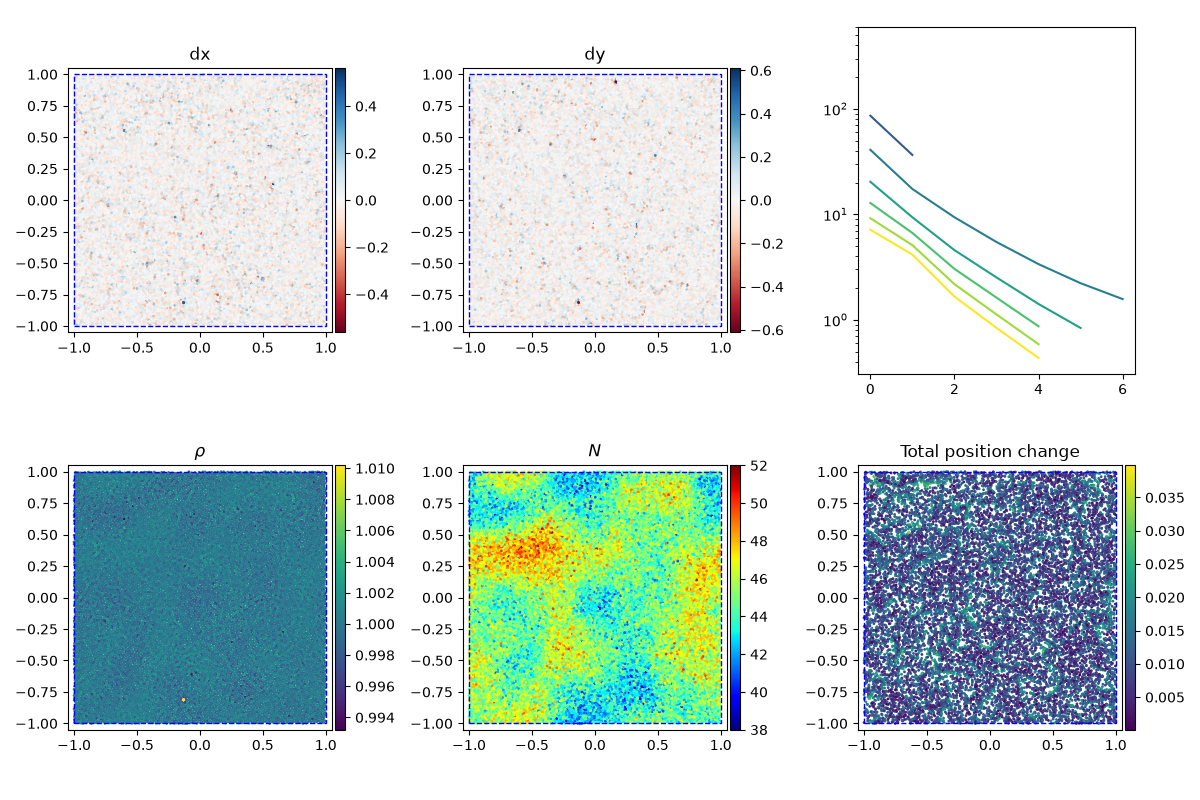

In [12]:
from diffSPH.v2.modules.shifting import solveShifting
import matplotlib.colors as mcolors

particleState = copy.deepcopy(initialState)
jitter = torch.normal(0, config['particle']['support'], particleState['fluid']['positions'].shape)

jitter = torch.rand(particleState['fluid']['positions'].shape) * config['particle']['dx'] - config['particle']['dx'] * 0.5

particleState['fluid']['positions'] += jitter * 0.5

particleState['fluid']['positions'] = torch.rand(particleState['fluid']['positions'].shape) * 8 - 4
initialPositions = torch.clone(particleState['fluid']['positions'])


config['shifting']['scheme'] = 'deltaSPH'
config['shifting']['scheme'] = 'IPS'
config['shifting']['freeSurface'] = False
config['shifting']['solver'] = 'BiCGStab_wJacobi'
config['shifting']['maxIterations'] = 8

config['shifting']['solver'] = 'BiCG'
config['shifting']['tol'] = 1e-1
config['shifting']['rtol'] = 1e-2
# # config['shifting']['solver'] = 'BiCGStab'
# config['shifting']['maxSolveIter'] = 64
# config['shifting']['freeSurface'] = False
# config['shifting']['summationDensity'] = False
# config['shifting']['scheme'] = 'IPS'
# config['shifting']['maxIterations'] = 32
config['shifting']['initialization'] = 'zero'
config['shifting']['preconditioner'] = 'Jacobi'
config['shifting']['verbose'] = True
# config['shifting']['threshold'] = 0.5
config['shifting']['solverThreshold'] = config['particle']['dx'] * .5


dx, states = solveShifting(particleState, config)
# jitter = torch.rand(particleState['fluid']['positions'].shape) * config['particle']['dx'] - config['particle']['dx'] * 0.5
particleState['fluid']['positions'] += dx

plotState(particleState, config)